# Module 13 · Project refinement, reproducibility, and AI-output verification
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **Can someone else rerun your result, and what evidence would expose a plausible but wrong answer?**

Guided work: about 40–50 minutes. Project refinement: about 20–30 minutes. This improves the **existing sustained project**; it is not a seventh concept lab or a new project. The project still uses two or three methods overall. This notebook audits one Markov-chain component, not every project requirement.

[Course home](../index.html) · [Interactive lesson](../modules/module13.html) · [Project guide](../project-guide.html)

We revisit the bike-state model from Modules 2–5, keep a declared chronological information boundary, and separate reproducibility, computational correctness, and scientific adequacy. The intentionally faulty examples below are instructor-written teaching fixtures, not retrieved AI output. AI use is optional and requires no paid account.

## 1. Write the scientific claim before running the code
Let $C_t$ be completed system-wide rentals on day $t$ and define $S_t=\mathbf1\{C_t\ge4000\}$. State 1 means a high **observed-count day**, not a station-capacity shortage. The threshold is an analyst-declared scenario input; the data do not measure unmet demand, available bicycles, or causal intervention effects.

Here the boundary is explicitly inclusive. Some earlier modules used $C_t>4000$; no observed 2011 count equals 4000, so this sample's fitted states agree. A synthetic equality check below makes the convention testable instead of silently relying on the sample.

Fit one transition matrix using **January 1–August 31: 243 days and 242 within-training transitions**. Freeze it. For each of the **122 September–December targets**, use the previous observed state, including August 31 for September 1. This is a sequence of one-day forecasts, not a four-month forecast issued once on August 31. The whole year has appeared in earlier modules, so these are **reused development assessment** results, not a newly untouched final holdout.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})
SEED = 6231

Matplotlib is building the font cache; this may take a moment.


In [2]:
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/"data/bike_daily_2011.csv").is_file())
data_path = ROOT/"data/bike_daily_2011.csv"
source = json.loads((ROOT/"data/source_metadata.json").read_text())
data_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert data_sha256 == source["sample_sha256"]
bike = pd.read_csv(data_path, parse_dates=["dteday"])
assert bike.dteday.tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
assert bike.dteday.is_unique and bike.cnt.ge(0).all()
assert np.all(bike.cnt == np.floor(bike.cnt))
counts = bike.cnt.to_numpy(float)
assert len(counts) == 365 and not np.any(counts == 4000)
print("Verified 365 complete 2011 dates; unchanged CSV SHA-256:", data_sha256)

Verified 365 complete 2011 dates; unchanged CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329


The unchanged [UCI Bike Sharing sample](https://doi.org/10.24432/C5W894), Fanaee-T (2013), is supplied under CC BY 4.0. Units are completed rentals per calendar day, aggregated over the system. No rows are dropped, imputed, or fabricated. The checksum verifies identity with the bundled recorded file; by itself it does not authenticate provenance, establish licensing, or prove that the measurements answer the project question.

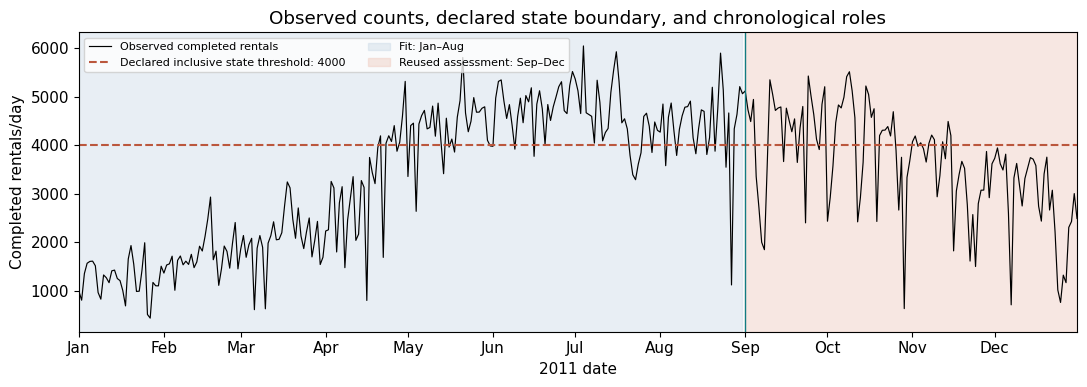

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bike.dteday, counts, color="black", linewidth=0.85, label="Observed completed rentals")
ax.axhline(4000, color="#bb573d", linestyle="--", label="Declared inclusive state threshold: 4000")
ax.axvspan(bike.dteday.iloc[0], bike.dteday.iloc[242], color="#c6d6e5", alpha=0.4, label="Fit: Jan–Aug")
ax.axvspan(bike.dteday.iloc[243], bike.dteday.iloc[-1], color="#edc4b7", alpha=0.4, label="Reused assessment: Sep–Dec")
ax.axvline(bike.dteday.iloc[243], color="#117c83", linewidth=1)
ax.set(xlim=(bike.dteday.iloc[0], bike.dteday.iloc[-1]), ylabel="Completed rentals/day", xlabel="2011 date", title="Observed counts, declared state boundary, and chronological roles")
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(fontsize=8, ncol=2); fig.tight_layout(); plt.show()

## 2. Turn assumptions into small functions with explicit inputs
For a row-stochastic matrix, $P_{ij}=P(S_{t+1}=j\mid S_t=i)$ and a row distribution advances as $\mu_h=\mu_0P^h$. Estimate
$$N_{ij}=\sum_{t=0}^{241}\mathbf1\{S_t=i,S_{t+1}=j\},\qquad \widehat P_{ij}=\frac{N_{ij}}{\sum_j N_{ij}}.$$
Normalize **across each row**, not down columns. If a training state has no outgoing transition, this likelihood estimate is undefined; raise an error or declare a separate prior model. Silently filling an empty row hides an assumption. Fitting one homogeneous first-order chain does not establish that the observed system truly has those properties.

In [4]:
def states_from_counts(values, threshold):
    values = np.asarray(values, float)
    if values.ndim != 1 or not np.isfinite(values).all(): raise ValueError("Finite 1D counts required")
    if np.any(values < 0) or np.any(values != np.floor(values)): raise ValueError("Nonnegative integer counts required")
    if not np.isfinite(threshold) or threshold < 0: raise ValueError("Finite nonnegative threshold required")
    return (values >= threshold).astype(int)
def validate_transition(P):
    P = np.asarray(P, float)
    if P.shape != (2, 2) or not np.isfinite(P).all(): raise ValueError("Finite 2 by 2 matrix required")
    if np.any(P < 0) or np.any(P > 1): raise ValueError("Probabilities outside [0,1]")
    if not np.allclose(P.sum(axis=1), 1, atol=1e-12, rtol=0): raise ValueError("Rows must sum to one")
    return P

In [5]:
def fit_transition(states):
    states = np.asarray(states)
    if states.ndim != 1 or len(states) < 2 or not np.isin(states, [0, 1]).all(): raise ValueError("Binary history required")
    N = np.zeros((2, 2), dtype=int)
    np.add.at(N, (states[:-1].astype(int), states[1:].astype(int)), 1)
    if np.any(N.sum(axis=1) == 0): raise ValueError("No outgoing observations for one training state")
    return N, validate_transition(N/N.sum(axis=1, keepdims=True))
def scenario_matrix(P, factor):
    P = validate_transition(P)
    if not np.isfinite(factor) or factor < 0: raise ValueError("Finite nonnegative scenario factor required")
    a, b = factor*P[0, 1], P[1, 0]
    return validate_transition([[1-a, a], [b, 1-b]])

For $P=\begin{pmatrix}1-a&a\\b&1-b\end{pmatrix}$ and a known starting state $s\in\{0,1\}$,
$$p_h=P(S_h=1\mid S_0=s)=\pi_1+(s-\pi_1)(1-a-b)^h,\quad \pi_1=\frac a{a+b},\quad a+b>0.$$
If $a=b=0$, then $P=I$ and $p_h=s$. The finite-horizon formula also holds for the alternating chain $a=b=1$, although its distribution does not converge. For a hand check, $a=0.2,b=0.3,s=0,h=2$ gives $p_2=0.8(0.2)+0.2(0.7)=0.30$.

A scenario factor $c\in\{0.5,1,1.5\}$ replaces **only** $a$ by $ca$, holding $b$ fixed. It must satisfy $ca\le1$. This is an unmeasured transition scenario, not evidence that a policy causes that change.

In [6]:
def check_discrete(start, horizon, replicas=1, seed=0):
    values = [start, horizon, replicas, seed]
    if any(isinstance(x, (bool, np.bool_)) or not isinstance(x, (int, np.integer)) for x in values):
        raise ValueError("Start, horizon, replications, and seed must be integers")
    if start not in [0, 1] or horizon < 0 or replicas < 1 or not 0 <= seed <= 2**32-1:
        raise ValueError("Invalid state, horizon, replication count, or seed")
def closed_high(P, start, horizon):
    P = validate_transition(P); check_discrete(start, horizon)
    a, b = P[0, 1], P[1, 0]
    if a+b == 0: return float(start)
    stationary_high = a/(a+b)
    return stationary_high+(start-stationary_high)*(1-a-b)**horizon

In [7]:
def simulate_terminal(P, start, horizon, replicas, seed):
    P = validate_transition(P); check_discrete(start, horizon, replicas, seed)
    rng = np.random.default_rng(seed)  # Construct once per run; advance across all paths and steps.
    terminal = np.full(replicas, start, dtype=int)
    for step in range(horizon):
        terminal = (rng.random(replicas) < P[terminal, 1]).astype(int)
    return terminal
def bad_reseed(P, start, horizon, replicas, seed):
    # DELIBERATE FAULT: every path restarts the same random stream.
    return np.array([simulate_terminal(P, start, horizon, 1, seed)[0] for _ in range(replicas)])

## 3. One configuration, one complete run
The function below fits from the declared prefix, issues frozen-matrix one-day forecasts, scores their common targets, and simulates a separate synthetic scenario. Inputs are explicit; the function creates its own random generator, so a prior call cannot consume its random stream. Dates, threshold convention, forecast origin, horizon, scenario, replication count, and seed belong in the recipe.

The real-data forecast uses the fitted matrix at factor 1. The scenario simulation changes only the declared synthetic transition matrix; it does not quietly replace the assessed forecast. The simulation starts in state 0, runs seven transitions, and asks whether the terminal state is high.

In [8]:
CONFIG = dict(data_start="2011-01-01", train_end="2011-08-31", assessment_end="2011-12-31",
    threshold=4000, inclusive=True, origin_policy="frozen_transition_previous_observed_state",
    horizon=7, start=0, scenario_factor=1.0, replications=10000, seed=SEED)
def run(config, values):
    states = states_from_counts(values, config["threshold"])
    dates = pd.date_range(config["data_start"], periods=len(states))
    cutoff = (pd.Timestamp(config["train_end"])-dates[0]).days+1
    if not 2 <= cutoff < len(states) or dates[-1] != pd.Timestamp(config["assessment_end"]): raise ValueError("Invalid data-role dates")
    if config["inclusive"] is not True or config["origin_policy"] != "frozen_transition_previous_observed_state": raise ValueError("Unsupported information rule")
    N, P = fit_transition(states[:cutoff]); Q = scenario_matrix(P, config["scenario_factor"])
    actual, previous = states[cutoff:], states[cutoff-1:-1]
    forecast = P[previous, 1]; terminal = simulate_terminal(Q, config["start"], config["horizon"], config["replications"], config["seed"])
    exact = closed_high(Q, config["start"], config["horizon"]); estimate = terminal.mean()
    return dict(N=N, P=P, Q=Q, cutoff=cutoff, actual=actual, forecast=forecast, persistence=previous,
        exact=exact, estimate=estimate, terminal=terminal, mcse=np.sqrt(estimate*(1-estimate)/len(terminal)),
        oracle_se=np.sqrt(exact*(1-exact)/len(terminal)), brier=np.mean((forecast-actual)**2), baseline_brier=np.mean((previous-actual)**2))

In [9]:
result = run(CONFIG, counts)
assert result["N"].sum() == 242 and len(result["actual"]) == 122
assert states_from_counts([3999, 4000, 4001], 4000).tolist() == [0, 1, 1]
display(pd.DataFrame(result["N"], index=["From low", "From high"], columns=["To low", "To high"]))
display(pd.DataFrame(result["P"], index=["From low", "From high"], columns=["To low", "To high"]))
print("Conditional 7-day exact / simulated high probability:", result["exact"], result["estimate"])
print("Brier: frozen chain / persistence:", result["brier"], result["baseline_brier"])

,To low,To high
From low,114,20
From high,19,89


,To low,To high
From low,0.850746,0.149254
From high,0.175926,0.824074


Conditional 7-day exact / simulated high probability: 0.4297389886172236 0.4325
Brier: frozen chain / persistence: 0.1748870579486289 0.22131147540983606


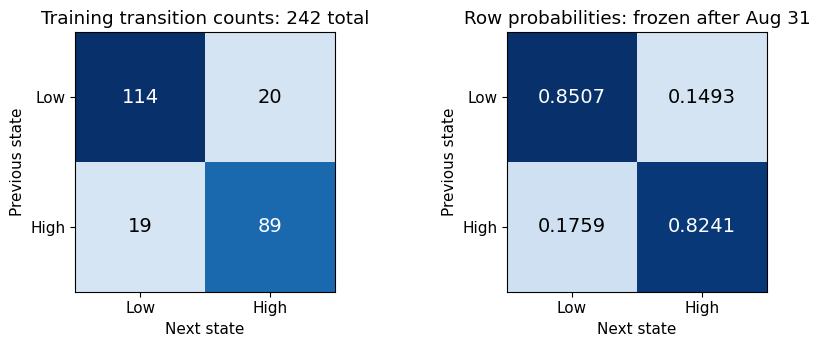

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, matrix, title, fmt in zip(axes, [result["N"], result["P"]], ["Training transition counts: 242 total", "Row probabilities: frozen after Aug 31"], ["d", ".4f"]):
    ax.imshow(matrix, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", color="white" if matrix[i, j] > matrix.max()*0.55 else "black", fontsize=14)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Low", "High"], yticklabels=["Low", "High"], xlabel="Next state", ylabel="Previous state", title=title)
fig.tight_layout(); plt.show()

## 4. Triangulate computation with independent mathematics
An exact matrix power and a two-state closed form provide separate derivations. They should agree for the same declared model; neither proves that the model is adequate for bike counts. Include boundaries: $h=0$, an absorbing state, an identity matrix, and a periodic alternating matrix. Reject invalid probabilities rather than silently clipping or renormalizing them.

In [11]:
fixture = np.array([[0.8, 0.2], [0.3, 0.7]])
assert np.isclose(closed_high(fixture, 0, 2), 0.30)
assert np.isclose(np.linalg.matrix_power(fixture, 2)[0, 1], 0.30)
for P in [fixture, np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[1, 0], [0.3, 0.7]]), result["P"]]:
    for start in [0, 1]:
        for horizon in [0, 1, 2, 7, 14]:
            assert np.isclose(closed_high(P, start, horizon), np.linalg.matrix_power(P, horizon)[start, 1])
assert np.array_equal(simulate_terminal(fixture, 1, 0, 20, SEED), np.ones(20))
print("PASS: hand calculation, independent matrix powers, zero horizon, absorbing/identity/alternating cases")

PASS: hand calculation, independent matrix powers, zero horizon, absorbing/identity/alternating cases


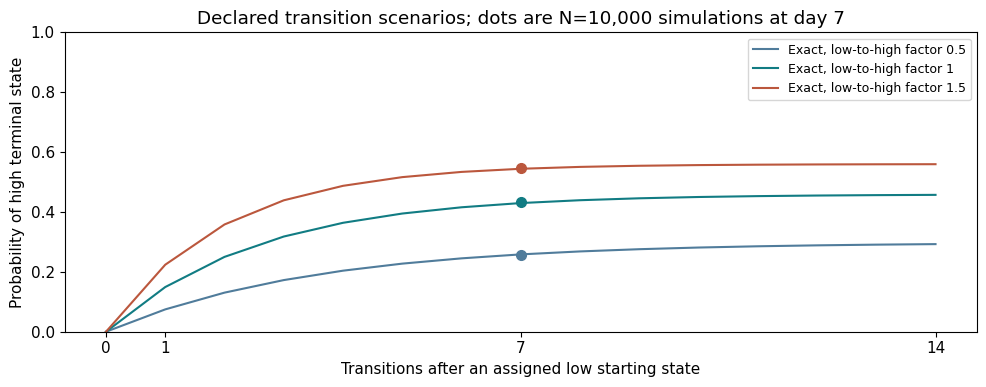

,factor,exact,simulation,MCSE
0,0.5,0.258296,0.2553,0.004360
1,1.0,0.429739,0.4325,0.004954
2,1.5,0.544261,0.5456,0.004979


In [12]:
horizons = np.arange(15); scenarios = []
fig, ax = plt.subplots(figsize=(10, 4))
for factor, color in zip([0.5, 1., 1.5], ["#507c9b", "#117c83", "#bb573d"]):
    trial = run({**CONFIG, "scenario_factor": factor}, counts)
    curve = [closed_high(trial["Q"], 0, int(h)) for h in horizons]
    scenarios.append(dict(factor=factor, exact=trial["exact"], simulation=trial["estimate"], MCSE=trial["mcse"]))
    ax.plot(horizons, curve, color=color, label=f"Exact, low-to-high factor {factor:g}")
    ax.plot(7, trial["estimate"], "o", color=color, markersize=7)
ax.set(xlabel="Transitions after an assigned low starting state", ylabel="Probability of high terminal state", title="Declared transition scenarios; dots are N=10,000 simulations at day 7", xticks=[0, 1, 7, 14], ylim=(0, 1))
ax.legend(fontsize=9); fig.tight_layout(); plt.show()
display(pd.DataFrame(scenarios))

## 5. Reproducible randomness can still be wrong
For independent synthetic terminal indicators $I_r$, $\widehat p=N^{-1}\sum_{r=1}^N I_r$. Its **conditional** Monte Carlo standard error is estimated by
$$\widehat{\operatorname{MCSE}}=\sqrt{\widehat p(1-\widehat p)/N},\quad
\operatorname{SE}_{\text{oracle}}=\sqrt{p_h(1-p_h)/N}\le\frac1{2\sqrt N}.$$
The oracle formula is available here because the finite-state probability is exact. More paths reduce computational error conditional on the fitted matrix; they do not supply more observations or remove parameter uncertainty, nonstationarity, or a wrong state definition.

**Deliberate fault:** restarting the same seed inside each path creates identical paths. Averaging $N$ copies does not create $N$ independent observations. The naive plug-in MCSE is then zero because all terminal indicators agree, but its independence premise is false. Repeatability alone cannot detect this error. Even a legitimate independent Bernoulli sample can produce an estimated MCSE of zero at a small sample boundary; zero plug-in MCSE is not a general proof of certainty.

,N,exact,estimate,MCSE,oracle_SE,SE_bound,bad_estimate,invalid_naive_MCSE
0,100,0.429739,0.3500,0.047697,0.049504,0.050000,0.0,0.0
1,1000,0.429739,0.4350,0.015677,0.015655,0.015811,0.0,0.0
2,10000,0.429739,0.4325,0.004954,0.004950,0.005000,0.0,0.0


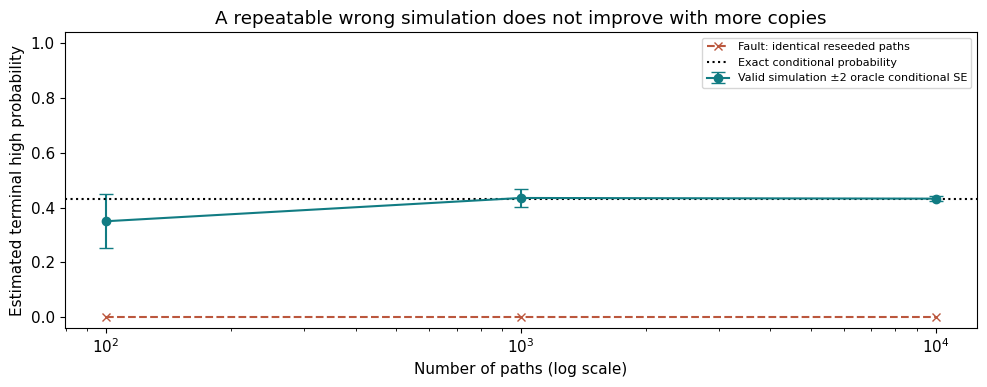

In [13]:
mc_rows = []
for replicas in [100, 1000, 10000]:
    good = run({**CONFIG, "replications": replicas}, counts)
    bad = bad_reseed(result["Q"], 0, 7, replicas, SEED)
    mc_rows.append(dict(N=replicas, exact=good["exact"], estimate=good["estimate"], MCSE=good["mcse"],
        oracle_SE=good["oracle_se"], SE_bound=1/(2*np.sqrt(replicas)), bad_estimate=bad.mean(), invalid_naive_MCSE=np.sqrt(bad.mean()*(1-bad.mean())/replicas)))
mc = pd.DataFrame(mc_rows); display(mc)
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(mc.N, mc.estimate, yerr=2*mc.oracle_SE, fmt="o-", color="#117c83", capsize=5, label="Valid simulation ±2 oracle conditional SE")
ax.plot(mc.N, mc.bad_estimate, "x--", color="#bb573d", label="Fault: identical reseeded paths")
ax.axhline(result["exact"], color="black", linestyle=":", label="Exact conditional probability")
ax.set(xscale="log", xticks=[100, 1000, 10000], xlabel="Number of paths (log scale)", ylabel="Estimated terminal high probability", ylim=(-0.04, 1.04), title="A repeatable wrong simulation does not improve with more copies")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

The displayed ±2 oracle-SE bars are a **conditional error-scale illustration**, not guaranteed confidence bounds. A single simulated error need not shrink monotonically with $N$; the variance scales as $1/N$. NumPy and the browser use different generators and draw orders, so their estimates need not match draw-for-draw. Replaying a recorded recipe within the same implementation should reproduce its stream.

In [14]:
replay = run(CONFIG, counts)
assert np.array_equal(result["terminal"], replay["terminal"])
new_seed = run({**CONFIG, "seed": SEED+1}, counts)
assert np.array_equal(result["P"], new_seed["P"]) and result["exact"] == new_seed["exact"]
assert not np.array_equal(result["terminal"], new_seed["terminal"])
print("PASS: complete same-seed replay; a new seed changes this synthetic stream, not its exact model probability")
print("Seed 6231 / 6232 estimates:", result["estimate"], new_seed["estimate"])

PASS: complete same-seed replay; a new seed changes this synthetic stream, not its exact model probability
Seed 6231 / 6232 estimates: 0.4325 0.437


## 6. Audit what the model predicts from real data
For target day $t$, the frozen-chain probability is $q_t=\widehat P_{S_{t-1},1}$; deterministic persistence uses $q_t^{\rm persist}=S_{t-1}$. Evaluate the same 122 outcomes using the Brier loss $n^{-1}\sum_t(q_t-S_t)^2$. Lower is better for this high-count event. It does not score rental-count magnitudes, identify a causal effect, or establish superior performance on future years.

Mutating the count on day $t$ must not alter its own forecast or earlier forecasts. It may alter day $t+1$'s forecast if the state flips; later targets then resume using their own previous observed states. Because the fitted matrix stays frozen, this example has no subsequent parameter refitting.

In [15]:
target = 260  # September 18; zero-based January 1 index.
changed = counts.copy(); changed[target] = 0 if counts[target] >= 4000 else 4000
mutated = run(CONFIG, changed)
position = target-result["cutoff"]
assert np.array_equal(mutated["P"], result["P"])
assert np.array_equal(mutated["forecast"][:position+1], result["forecast"][:position+1])
assert mutated["forecast"][position+1] != result["forecast"][position+1]
assert np.array_equal(mutated["forecast"][position+2:], result["forecast"][position+2:])
assert mutated["actual"][position] != result["actual"][position]
print("PASS: a changed target changes its score and only the next day's state-based forecast; P stays frozen")
print(pd.DataFrame({"method": ["Frozen chain", "Persistence"], "Brier": [result["brier"], result["baseline_brier"]]}))

PASS: a changed target changes its score and only the next day's state-based forecast; P stays frozen
         method     Brier
0  Frozen chain  0.174887
1   Persistence  0.221311


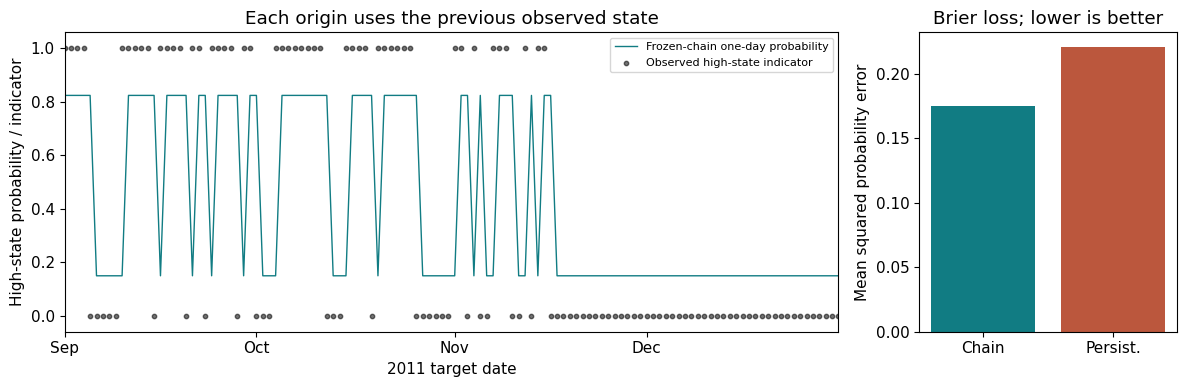

In [16]:
dates = bike.dteday.iloc[result["cutoff"]:]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(dates, result["forecast"], color="#117c83", linewidth=1, label="Frozen-chain one-day probability")
axes[0].scatter(dates, result["actual"], s=10, color="black", alpha=0.55, label="Observed high-state indicator")
axes[0].set(xlim=(dates.iloc[0], dates.iloc[-1]), ylim=(-0.06, 1.06), xlabel="2011 target date", ylabel="High-state probability / indicator", title="Each origin uses the previous observed state")
axes[0].xaxis.set_major_locator(mdates.MonthLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b")); axes[0].legend(fontsize=8)
axes[1].bar(["Chain", "Persist."], [result["brier"], result["baseline_brier"]], color=["#117c83", "#bb573d"])
axes[1].set(ylabel="Mean squared probability error", title="Brier loss; lower is better")
fig.tight_layout(); plt.show()

An honest result can be reproducible yet scientifically limited. The two-state chain compresses all rental magnitudes into one bit, estimates a constant matrix across seasons, and assumes the previous state is sufficient. The observed September–December score is evidence about this declared reused assessment, not proof of those assumptions. A model improvement should answer the project's decision question and preserve the comparison's information boundary.

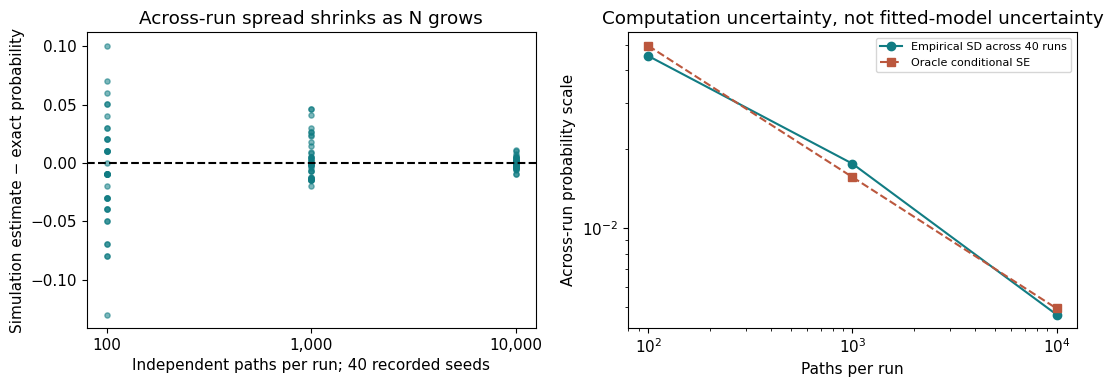

,N,empirical_SD,oracle_SE
0,100,0.045285,0.049504
1,1000,0.017610,0.015655
2,10000,0.004691,0.004950


In [17]:
seed_rows = []
for replicas in [100, 1000, 10000]:
    estimates = np.array([simulate_terminal(result["Q"], 0, 7, replicas, SEED+j).mean() for j in range(40)])
    seed_rows.append(dict(N=replicas, empirical_SD=estimates.std(ddof=1), oracle_SE=np.sqrt(result["exact"]*(1-result["exact"])/replicas), estimates=estimates))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for j, row in enumerate(seed_rows):
    axes[0].scatter(np.full(40, j), row["estimates"]-result["exact"], s=14, alpha=0.55, color="#117c83")
axes[0].axhline(0, color="black", linestyle="--"); axes[0].set(xticks=range(3), xticklabels=["100", "1,000", "10,000"], xlabel="Independent paths per run; 40 recorded seeds", ylabel="Simulation estimate − exact probability", title="Across-run spread shrinks as N grows")
axes[1].loglog([r["N"] for r in seed_rows], [r["empirical_SD"] for r in seed_rows], "o-", color="#117c83", label="Empirical SD across 40 runs")
axes[1].loglog([r["N"] for r in seed_rows], [r["oracle_SE"] for r in seed_rows], "s--", color="#bb573d", label="Oracle conditional SE")
axes[1].set(xlabel="Paths per run", ylabel="Across-run probability scale", title="Computation uncertainty, not fitted-model uncertainty"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
display(pd.DataFrame([{k: v for k, v in r.items() if k != "estimates"} for r in seed_rows]))

## 7. Save a recipe and an evidence trail, not just a seed
A reproducibility manifest records raw data identity, source and license, units, dates, code identity, every consequential configuration value, software versions, and a compact result. It should also point to fresh-kernel verification. The manifest below stays **in memory** and prints; it writes no new files by default. Exporting it can be part of the existing project's reproducibility package.

Hashing the whole executed notebook is unstable because saved outputs change. Our **source fingerprint** hashes only each cell's `cell_type` and source text, in saved cell order; outputs, execution counts, IDs, and metadata are excluded. We serialize JSON with sorted keys, compact separators, UTF-8, and no ASCII escaping. The configuration fingerprint uses the same convention. This scope is explicit: a source hash does not verify outputs or external dependencies. Different canonicalization conventions can legitimately yield different hashes.

The displayed versions are a tested direct-dependency snapshot, not a complete transitive dependency lock or a guarantee of identical numerical libraries on every machine. A fresh kernel checks hidden execution state; the surrounding verification record documents which reruns were actually completed.

In [18]:
def canonical_json(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
def sha256_json(value):
    return hashlib.sha256(canonical_json(value).encode("utf-8")).hexdigest()
notebook_path = ROOT/"notebooks/module13_reproducibility_verification.ipynb"
saved = json.loads(notebook_path.read_text())
source_cells = [{"cell_type": c["cell_type"], "source": "".join(c["source"])} for c in saved["cells"]]
source_fingerprint = sha256_json(source_cells)
versions = {p: metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]}
summary = {key: float(result[key]) for key in ["exact", "estimate", "mcse", "oracle_se", "brier", "baseline_brier"]}

In [19]:
manifest = dict(data=dict(sha256=data_sha256, rows=len(bike), start=str(bike.dteday.iloc[0].date()), end=str(bike.dteday.iloc[-1].date()),
    units=source["units"]["cnt"], source_doi=source["doi"], license=source["license"]),
    configuration=CONFIG, configuration_sha256=sha256_json(CONFIG),
    source_fingerprint=dict(sha256=source_fingerprint, scope="ordered cell_type and source only; compact sorted-key UTF-8 JSON"),
    software=dict(python=platform.python_version(), packages=versions, numpy_generator="default_rng / "+type(np.random.default_rng(CONFIG["seed"]).bit_generator).__name__),
    output=dict(summary, transition_counts=result["N"].tolist(), fitted_P=result["P"].tolist(), scenario_P=result["Q"].tolist()),
    verification=dict(recipe="restart kernel and run all, from course root or notebooks directory", record="README.md#maintain-and-verify"))
print(json.dumps(manifest, indent=2, ensure_ascii=False))
assert sha256_json(CONFIG) == sha256_json(dict(reversed(list(CONFIG.items()))))
assert sha256_json(CONFIG) != sha256_json({**CONFIG, "seed": SEED+1})
print("PASS: configuration hash ignores key insertion order and detects the declared seed change")

{
  "data": {
    "sha256": "fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329",
    "rows": 365,
    "start": "2011-01-01",
    "end": "2011-12-31",
    "units": "completed rentals per calendar day (not unique bicycles or latent demand)",
    "source_doi": "10.24432/C5W894",
    "license": "CC BY 4.0"
  },
  "configuration": {
    "data_start": "2011-01-01",
    "train_end": "2011-08-31",
    "assessment_end": "2011-12-31",
    "threshold": 4000,
    "inclusive": true,
    "origin_policy": "frozen_transition_previous_observed_state",
    "horizon": 7,
    "start": 0,
    "scenario_factor": 1.0,
    "replications": 10000,
    "seed": 6231
  },
  "configuration_sha256": "8ef1d33c1a741602a1d9245ef1f90bac0206fcd1b0ca9ca325a393d9c59ed067",
  "source_fingerprint": {
    "sha256": "2748c0aa4b08fc6fe9e4f09584f06f9bbea93a0c46e606e08f57a1aff2486883",
    "scope": "ordered cell_type and source only; compact sorted-key UTF-8 JSON"
  },
  "software": {
    "python": "3.10.9",
    "p

## 8. Audit optional AI help with evidence outside the answer
This **deliberately flawed, instructor-written AI-style proposal** is discussion material. Do not execute it as a valid method:
```python
states = (all_counts >= 4000).astype(int)
N = transition_counts(states)       # future assessment outcomes enter the fit
P = N / N.sum(axis=0)               # normalizes columns, not transition rows
for path in range(10000):
    rng = np.random.default_rng(6231)  # identical stream for every path
    terminal[path] = simulate_one(P, rng)
# Claim: 10,000 independent paths prove a capacity intervention succeeds.
```

A useful audit log pairs each consequential suggestion with an independent calculation, invariant, data-boundary check, or primary reference; it states what failed, what changed, and what claim remains supportable. Agreement from a second AI answer is not independent mathematical evidence. A passing program still cannot establish homogeneity, the Markov property, measurement validity, or a causal effect. You retain responsibility for the final argument and should be able to explain one equation and one failure case individually.

For the existing project, connect the audit to a decision: compare two or three methods overall, justify the observed target and baseline, identify the uncertainty affecting that decision, preserve a valid evaluation boundary, and record the revision motivated by the evidence. Do not turn a collection of passing checks into an arbitrary readiness score.

## 9. Four investigations · your project refinement
These cells remain unanswered. Adapt the worked audit to the existing project and its existing deliverables; no additional concept-lab submission or new project is assigned.

### E1 — Make the result replayable
Run the declared bike-state analysis from a fresh kernel and record the raw CSV checksum, source-only notebook fingerprint, complete configuration, software versions, and output summary. Repeat the same seed, then change only the seed and compare exact probabilities, simulation estimates, and conditional Monte Carlo standard errors. Explain why an identical seed or hash alone does not verify a scientific claim.

In [20]:
# YOUR WORK — E1
# Add your calculation, evidence, and short interpretation here.

### E2 — Build checks that can catch a wrong answer
Add two independently justified checks beyond simple seed replay: use a hand-computable transition fixture or a limiting case, and a chronology or input-validity test. Audit the deliberately flawed AI-style proposal for column normalization, future-data fitting, per-path reseeding, false independence, and a capacity claim. Record an expected failure before the repair and a passing check afterward; explain what the checks still cannot establish.

In [21]:
# YOUR WORK — E2
# Add your calculation, evidence, and short interpretation here.

### E3 — Refine the model without overstating the evidence
Compare the frozen chain and deterministic persistence on the same 122 September–December one-day state targets using Brier loss. Change a future count enough to flip its state and identify which forecasts can change. Compare factors 0.5, 1, and 1.5 on the low-to-high transition probability, holding the high-to-low probability fixed; distinguish conditional Monte Carlo error, fitted-parameter uncertainty, structural uncertainty, and an unmeasured scenario from a causal intervention.

In [22]:
# YOUR WORK — E3
# Add your calculation, evidence, and short interpretation here.

### E4 — Turn an audit into a project revision
For the existing project, write a brief decision-focused revision record: question and units, two or three methods overall, data and information boundaries, comparison baseline, uncertainty and sensitivity evidence, reproducibility recipe, and one remaining limitation. Include a concise optional-AI audit log naming consequential suggestions, independent checks, corrections, and retained responsibility. Prepare an individual explanation of one formula and one failure case; no additional lab or new project is required.

In [23]:
# YOUR WORK — E4
# Add your calculation, evidence, and short interpretation here.

## 10. Optional extension and next step
For a larger project, separate independent data validation from numerical tests, record a fuller environment lock, and let another person reproduce a decision-relevant table from a fresh checkout. If a revised model is motivated by previously assessed outcomes, return to development and reserve genuinely new data before making another final-validation claim.

[Module 14](../modules/module14.html) brings the existing project into a six-minute presentation, an individual explanation, and the final reproducible handoff. Carry forward a reproducible result, an independently justified check, a documented correction, and a limitation that matters to the decision.

References and provenance: [UCI Bike Sharing](https://doi.org/10.24432/C5W894), Fanaee-T (2013), CC BY 4.0. The supplied MATH 6241 notes and earlier course modules provide the finite-state Markov-chain and Monte Carlo context. The reproducibility and AI-verification workflow here is an applied extension, not a claim that the source notes teach this exact audit. Supplemental workflow references: Sandve et al. (2013), [Ten Simple Rules for Reproducible Computational Research](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1003285); [NumPy random-stream compatibility](https://numpy.org/doc/stable/reference/random/compatibility.html); and [NBClient execution documentation](https://nbclient.readthedocs.io/en/latest/client.html).